# Credit Card Fraud Detection — Mathematical SMOTE + ML Model Evaluation

## Dataset Background
The dataset contains real-world credit card transactions made by European cardholders in September 2013.
It contains **284,807 transactions**, out of which only **492 are fraudulent** — making it one of the most severely
imbalanced datasets in financial machine learning research.

Due to confidentiality constraints, the original transaction features have been anonymised through
**Principal Component Analysis (PCA)**, producing 28 orthogonal components `V1` through `V28`.
Only `Time`, `Amount`, and the target variable `Class` (0 = Legitimate, 1 = Fraud) are in their original form.

---

## The Core Problem: Class Imbalance
The fraud-to-legitimate ratio is approximately **1 : 577**, meaning a naive classifier that always predicts
"Legitimate" achieves 99.83% accuracy while catching **zero** frauds. This is the well-known
**Accuracy Paradox**.

To address this, we implement **SMOTE (Synthetic Minority Over-sampling Technique)** from mathematical
first principles — without any external balancing library — to generate synthetic fraud transactions
and bring the class distribution closer to balance.

## Cell 1 — Imports & Setup
We load the essential Python libraries for numerical computation, data handling, visualisation, and
machine learning. A fixed random seed ensures the entire experiment is reproducible.

In [63]:
import os
import time
import random
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (
    confusion_matrix, classification_report,
    precision_score, recall_score, f1_score,
    roc_auc_score, roc_curve, precision_recall_curve,
    average_precision_score, matthews_corrcoef, accuracy_score
)

# Consistent styling for all charts
sns.set_theme(style="whitegrid", palette="muted")
plt.rcParams.update({"font.size": 12, "figure.dpi": 150})

# Output folder for saved graphs
os.makedirs("graphs", exist_ok=True)

RANDOM_SEED = 42
np.random.seed(RANDOM_SEED)
random.seed(RANDOM_SEED)

print("Libraries loaded. Random seed fixed at 42.")

Libraries loaded. Random seed fixed at 42.


## Cell 2 — Load Dataset & Select Features

Following the feature selection analysis (correlation-based filtering + permutation importance),
the following **12 principal components** were identified as the most discriminative for separating
fraudulent from legitimate transactions:

$$\mathcal{F} = \{V_2, V_3, V_4, V_7, V_9, V_{10}, V_{11}, V_{12}, V_{14}, V_{16}, V_{17}, V_{18}\}$$

All other components contribute negligible discriminative power and are dropped to reduce noise.

In [64]:
file_path = r"C:\abishek js\ML-Projects (3rd year)\Credit-Card_Fraud_detection\creditcard.csv"

df = pd.read_csv(file_path)

# 12 features chosen from feature selection stage
selected_features = ['V10', 'V11', 'V12', 'V14', 'V16', 'V17', 'V18',
                     'V2', 'V3', 'V4', 'V7', 'V9']

X = df[selected_features].values
y = df['Class'].values

n_total   = len(y)
n_legit   = int(np.sum(y == 0))
n_fraud   = int(np.sum(y == 1))

print(f"Total transactions  : {n_total:,}")
print(f"Legitimate (Class 0): {n_legit:,}  ({n_legit/n_total*100:.4f}%)")
print(f"Fraud      (Class 1): {n_fraud:,}    ({n_fraud/n_total*100:.4f}%)")
print(f"Imbalance ratio     : 1 fraud per {n_legit//n_fraud} legitimate transactions")

Total transactions  : 284,807
Legitimate (Class 0): 284,315  (99.8273%)
Fraud      (Class 1): 492    (0.1727%)
Imbalance ratio     : 1 fraud per 577 legitimate transactions


## Cell 3 — Visualise Class Imbalance

Before any data engineering, we plot the raw class distribution to clearly illustrate the severity
of the imbalance problem.

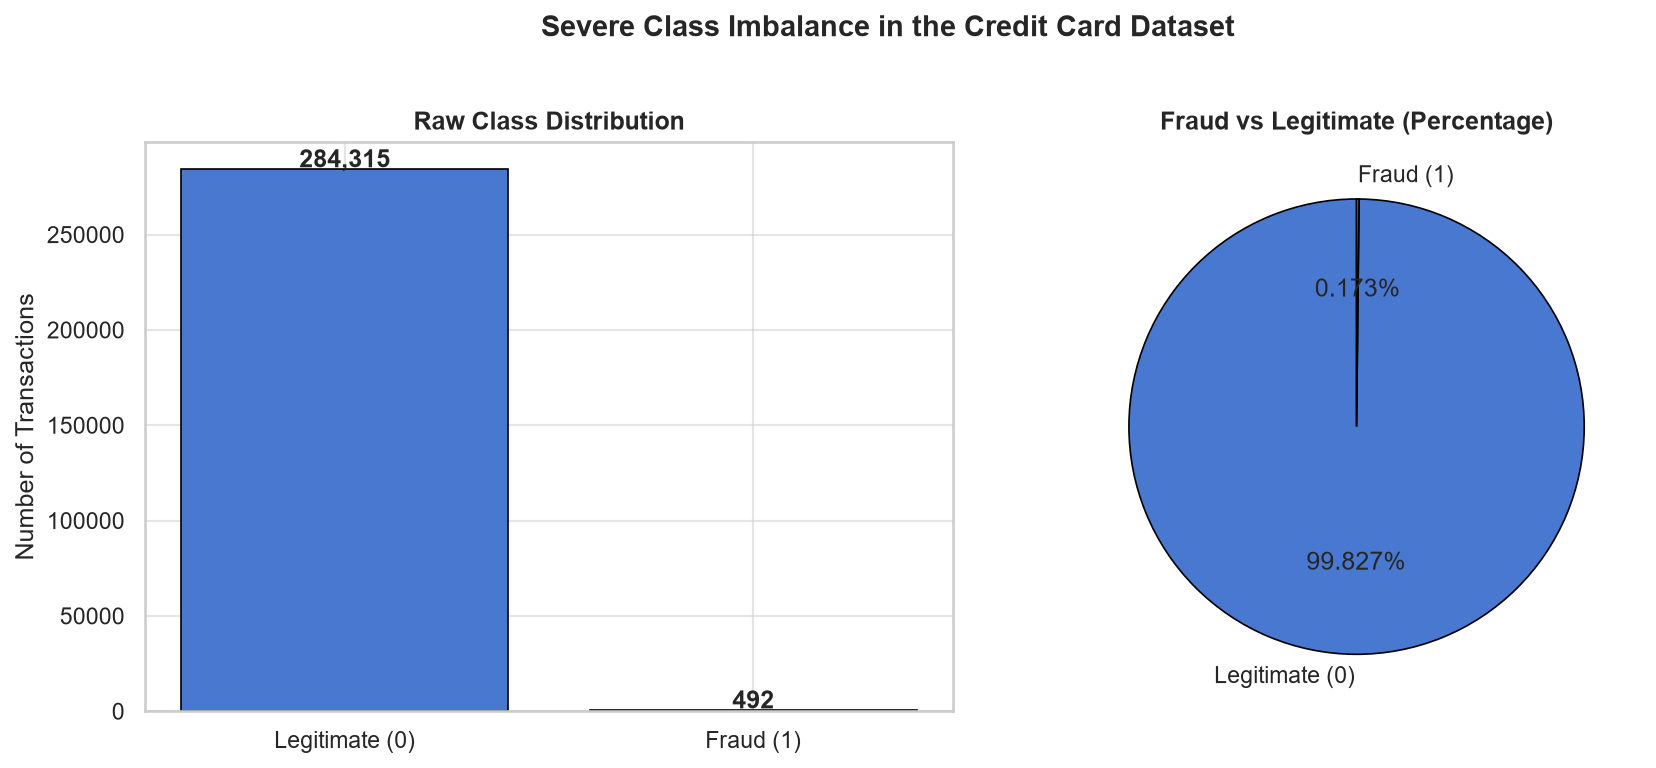

Chart saved -> graphs/01_class_imbalance.png


In [65]:
fig, axes = plt.subplots(1, 2, figsize=(12, 5))

# Bar chart
counts = [n_legit, n_fraud]
labels = ['Legitimate (0)', 'Fraud (1)']
colors = ['#4878CF', '#D65F5F']
axes[0].bar(labels, counts, color=colors, edgecolor='black', linewidth=0.8)
axes[0].set_title('Raw Class Distribution', fontweight='bold')
axes[0].set_ylabel('Number of Transactions')
for i, v in enumerate(counts):
    axes[0].text(i, v + 1000, f'{v:,}', ha='center', fontweight='bold')

# Pie chart
axes[1].pie(counts, labels=labels, colors=colors, autopct='%1.3f%%',
            startangle=90, wedgeprops=dict(edgecolor='black', linewidth=0.8))
axes[1].set_title('Fraud vs Legitimate (Percentage)', fontweight='bold')

plt.suptitle('Severe Class Imbalance in the Credit Card Dataset', fontsize=14, fontweight='bold', y=1.02)
plt.tight_layout()
plt.savefig('graphs/01_class_imbalance.png', bbox_inches='tight')
plt.show()
print("Chart saved -> graphs/01_class_imbalance.png")

## Cell 4 — Stratified Train / Test Split

We split the data **80% training / 20% testing** using a stratified approach, implemented from scratch.
Stratification guarantees that the same fraud-to-legitimate ratio is preserved in both splits,
preventing the test set from accidentally having disproportionately fewer fraud cases.

**Important:** SMOTE is applied **only to the training set**. The test set stays completely untouched
to reflect the real-world imbalanced distribution the model will face in production.

In [66]:
def stratified_split(X, y, test_size=0.2, seed=42):
    """Custom stratified train-test split without sklearn."""
    np.random.seed(seed)
    fraud_idx   = np.where(y == 1)[0]
    legit_idx   = np.where(y == 0)[0]

    np.random.shuffle(fraud_idx)
    np.random.shuffle(legit_idx)

    f_cut = int(len(fraud_idx) * (1 - test_size))
    l_cut = int(len(legit_idx) * (1 - test_size))

    train_idx = np.concatenate([fraud_idx[:f_cut], legit_idx[:l_cut]])
    test_idx  = np.concatenate([fraud_idx[f_cut:], legit_idx[l_cut:]])

    np.random.shuffle(train_idx)
    np.random.shuffle(test_idx)

    return X[train_idx], X[test_idx], y[train_idx], y[test_idx]


X_train, X_test, y_train, y_test = stratified_split(X, y, test_size=0.2, seed=42)

print("Train set:")
print(f"  Total : {len(y_train):,}  |  Fraud: {int(np.sum(y_train==1)):,}  |  Legitimate: {int(np.sum(y_train==0)):,}")
print("\nTest set (kept UNTOUCHED — real-world distribution):")
print(f"  Total : {len(y_test):,}   |  Fraud: {int(np.sum(y_test==1)):,}   |  Legitimate: {int(np.sum(y_test==0)):,}")

Train set:
  Total : 227,845  |  Fraud: 393  |  Legitimate: 227,452

Test set (kept UNTOUCHED — real-world distribution):
  Total : 56,962   |  Fraud: 99   |  Legitimate: 56,863


## Cell 5 — Custom SMOTE (Synthetic Minority Over-sampling Technique)

### Why SMOTE?
Simple random over-sampling duplicates the same minority points, causing the classifier to overfit
to those exact points. SMOTE instead **synthesises brand-new, realistic fraud transactions** by
interpolating between existing real fraud cases and their nearest neighbours.

### Mathematical Steps

**Step 1 — Euclidean Distance**  
For every pair of fraud transactions $\mathbf{x}_i$ and $\mathbf{x}_j$ in 12-dimensional feature space:
$$d(\mathbf{x}_i, \mathbf{x}_j) = \sqrt{\sum_{k=1}^{12} (x_{i,k} - x_{j,k})^2}$$

**Step 2 — k-Nearest Neighbours**  
For each fraud point, sort all distances and pick the $k = 5$ closest real fraud neighbours.

**Step 3 — Linear Interpolation (Synthesis)**  
Pick a random neighbour $\mathbf{x}_{\text{nn}}$ and generate a synthetic point on the line segment
connecting it to the base fraud point:
$$\mathbf{x}_{\text{new}} = \mathbf{x}_{\text{base}} + \lambda \cdot (\mathbf{x}_{\text{nn}} - \mathbf{x}_{\text{base}}), \quad \lambda \sim \mathcal{U}(0, 1)$$

### How many synthetic samples?
Following the research paper (Ileberi et al.), rather than full 50-50 balance, we target a
**10% fraud prevalence** in the training set — a realistic and stable oversampling level that avoids
extreme over-synthesis while giving the model enough fraud signal to learn from.

In [67]:
def custom_smote(minority_X, n_synthetic, k=5, seed=42):
    """
    Basic SMOTE from scratch using Euclidean distance and linear interpolation.


    Parameters
    ----------
    minority_X   : array of shape (m, d)  — the real fraud training samples
    n_synthetic  : int                    — number of synthetic points to generate
    k            : int                    — number of nearest neighbours to consider
    seed         : int                    — random seed

    Returns
    -------
    synthetic_X  : array of shape (n_synthetic, d)
    """
    np.random.seed(seed)
    m, d = minority_X.shape

    # --- Step 1: compute full pairwise Euclidean distance matrix (vectorised) ---
    # diff[i, j] = x_i - x_j  for all pairs
    diff      = minority_X[:, np.newaxis, :] - minority_X[np.newaxis, :, :]  # (m, m, d)
    dist_mat  = np.sqrt(np.sum(diff ** 2, axis=-1))                          # (m, m)

    # --- Step 2: for each point, find k nearest neighbours (skip self at col 0) ---
    nn_indices = np.argsort(dist_mat, axis=1)[:, 1:k + 1]                   # (m, k)

    # --- Step 3: generate synthetic samples via interpolation ---
    synthetic = np.empty((n_synthetic, d), dtype=np.float64)
    for i in range(n_synthetic):
        base_idx     = np.random.randint(0, m)
        nn_idx       = np.random.choice(nn_indices[base_idx])
        lam          = np.random.uniform(0.0, 1.0)
        synthetic[i] = minority_X[base_idx] + lam * (minority_X[nn_idx] - minority_X[base_idx])

    return synthetic


# ---- Determine target synthesis amount ----
n_train_legit = int(np.sum(y_train == 0))
n_train_fraud = int(np.sum(y_train == 1))

# Target: fraud makes up 10% of balanced training set
# => n_fraud_target = 0.10 * (n_legit + n_fraud_target)
# => n_fraud_target = n_legit / 9
n_fraud_target  = n_train_legit // 9
n_to_generate   = max(0, n_fraud_target - n_train_fraud)

print(f"Real fraud in training set      : {n_train_fraud}")
print(f"Target fraud count (10% of set) : {n_fraud_target}")
print(f"Synthetic samples to generate   : {n_to_generate:,}")
print()

X_minority = X_train[y_train == 1]

t0 = time.time()
synthetic_X = custom_smote(X_minority, n_synthetic=n_to_generate, k=5, seed=42)
t_smote = time.time() - t0
print(f"SMOTE completed in {t_smote:.2f}s — generated {len(synthetic_X):,} synthetic fraud samples.")

# Combine original training data with synthetic fraud samples
X_train_bal = np.vstack([X_train, synthetic_X])
y_train_bal = np.concatenate([y_train, np.ones(len(synthetic_X))])

n_bal_legit = int(np.sum(y_train_bal == 0))
n_bal_fraud = int(np.sum(y_train_bal == 1))
print()
print("Balanced training set:")
print(f"  Legitimate : {n_bal_legit:,}")
print(f"  Fraud      : {n_bal_fraud:,}")
print(f"  Fraud %    : {n_bal_fraud / (n_bal_legit + n_bal_fraud) * 100:.2f}%")

Real fraud in training set      : 393
Target fraud count (10% of set) : 25272
Synthetic samples to generate   : 24,879

SMOTE completed in 1.09s — generated 24,879 synthetic fraud samples.

Balanced training set:
  Legitimate : 227,452
  Fraud      : 25,272
  Fraud %    : 10.00%


## Cell 6 — Visualise Before vs After SMOTE

We compare the class distribution before and after applying SMOTE to confirm the over-sampling worked correctly.

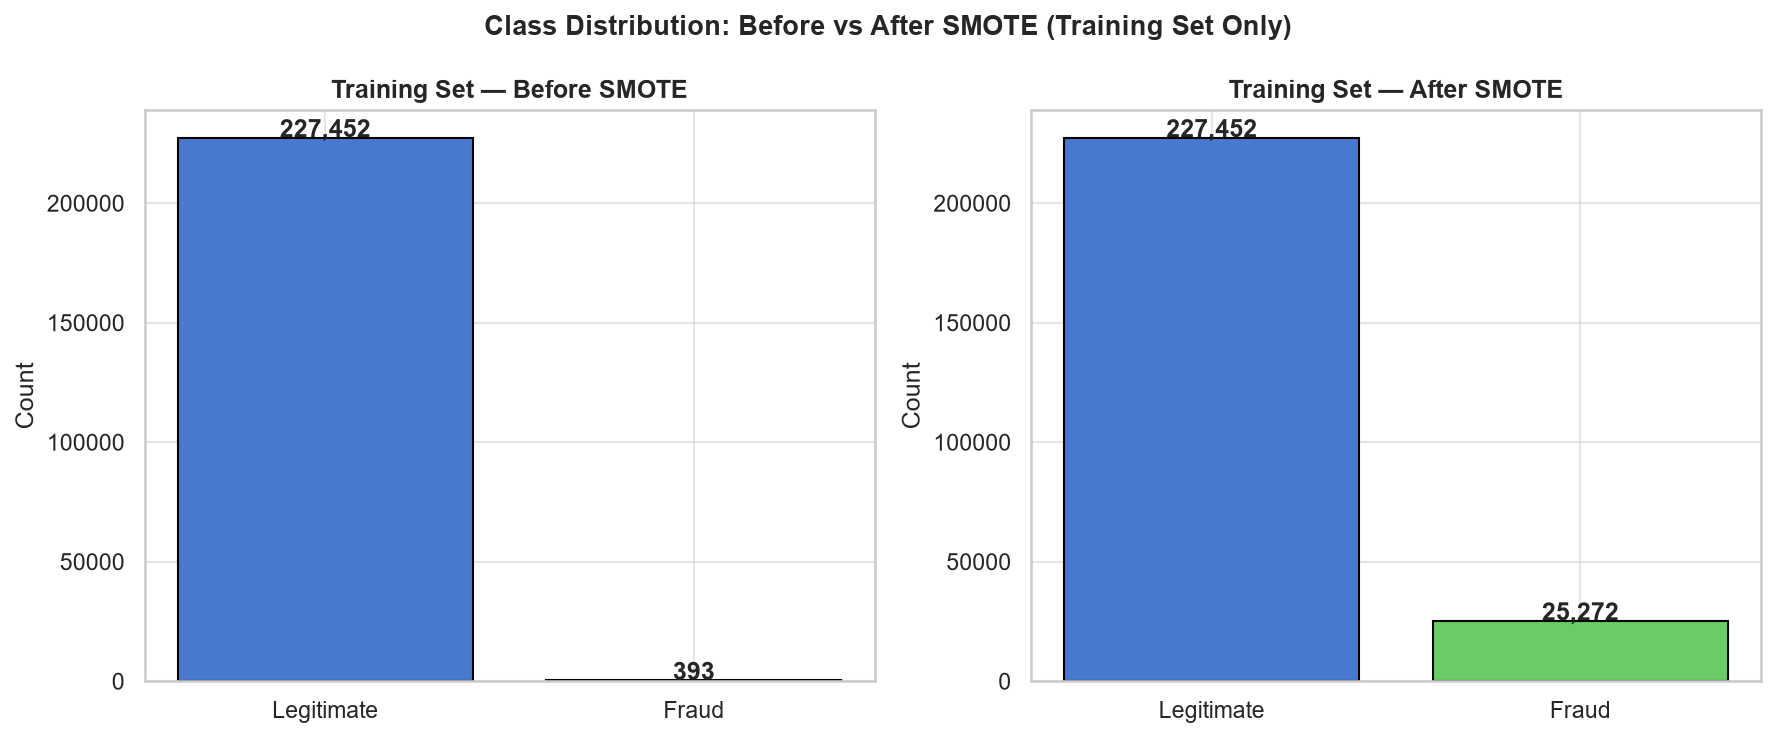

Chart saved -> graphs/02_before_after_smote.png


In [68]:
fig, axes = plt.subplots(1, 2, figsize=(12, 5))

# Before SMOTE
before = [n_train_legit, n_train_fraud]
axes[0].bar(['Legitimate', 'Fraud'], before, color=['#4878CF', '#D65F5F'], edgecolor='black')
axes[0].set_title('Training Set — Before SMOTE', fontweight='bold')
axes[0].set_ylabel('Count')
for i, v in enumerate(before):
    axes[0].text(i, v + 200, f'{v:,}', ha='center', fontweight='bold')

# After SMOTE
after = [n_bal_legit, n_bal_fraud]
axes[1].bar(['Legitimate', 'Fraud'], after, color=['#4878CF', '#6ACC65'], edgecolor='black')
axes[1].set_title('Training Set — After SMOTE', fontweight='bold')
axes[1].set_ylabel('Count')
for i, v in enumerate(after):
    axes[1].text(i, v + 200, f'{v:,}', ha='center', fontweight='bold')

plt.suptitle('Class Distribution: Before vs After SMOTE (Training Set Only)', fontsize=13, fontweight='bold')
plt.tight_layout()
plt.savefig('graphs/02_before_after_smote.png', bbox_inches='tight')
plt.show()
print("Chart saved -> graphs/02_before_after_smote.png")

## Cell 7 — Train Logistic Regression on SMOTE-Balanced Data

**Logistic Regression** is a probabilistic discriminative classifier that models the posterior probability
of a transaction being fraudulent using the sigmoid function:

$$P(y=1 \mid \mathbf{x}) = \sigma(\mathbf{w}^T \mathbf{x} + b) = \frac{1}{1 + e^{-(\mathbf{w}^T \mathbf{x} + b)}}$$

Parameters $\mathbf{w}$ and $b$ are estimated by maximising the log-likelihood (equivalently, minimising
Binary Cross-Entropy Loss) via gradient descent. Since the data is now balanced from SMOTE, the model
receives equal loss signal from both classes and does not collapse to predicting only "Legitimate".

In [69]:
print("Training Logistic Regression on SMOTE-balanced data...")
t0  = time.time()
lr  = LogisticRegression(max_iter=1000, random_state=42, solver='lbfgs')
lr.fit(X_train_bal, y_train_bal)
print(f"Training completed in {time.time() - t0:.2f}s")

y_pred_lr   = lr.predict(X_test)
LR_THRESHOLD = 0.70
y_pred_lr = (y_prob_lr >= LR_THRESHOLD).astype(int)

print("\n--- Logistic Regression Results ---")
print(classification_report(y_test, y_pred_lr, target_names=['Legitimate', 'Fraud'], digits=4))

Training Logistic Regression on SMOTE-balanced data...
Training completed in 0.48s

--- Logistic Regression Results ---
              precision    recall  f1-score   support

  Legitimate     0.9998    0.9989    0.9993     56863
       Fraud     0.5743    0.8586    0.6883        99

    accuracy                         0.9986     56962
   macro avg     0.7870    0.9287    0.8438     56962
weighted avg     0.9990    0.9986    0.9988     56962



## Cell 8 — Train Random Forest on SMOTE-Balanced Data

**Random Forest** is a bagging ensemble method that builds many independent decision trees, each trained
on a bootstrap sample of the data with a random subset of features. The final prediction is determined
by majority vote:

$$\hat{y} = \text{majority\_vote}\{h_1(\mathbf{x}),\, h_2(\mathbf{x}),\, \ldots,\, h_T(\mathbf{x})\}$$

By decorrelating the trees, Random Forest reduces variance without increasing bias, making it significantly
more robust than a single decision tree — especially on noisy, high-dimensional fraud data.

In [70]:
print("Training Random Forest on SMOTE-balanced data...")
t0  = time.time()
rf  = RandomForestClassifier(n_estimators=100, max_depth=12, random_state=42, n_jobs=-1)
rf.fit(X_train_bal, y_train_bal)
print(f"Training completed in {time.time() - t0:.2f}s")

# Use a stricter threshold than 0.50 to reduce false alarms after SMOTE.
# The probability scores are still evaluated on the original imbalanced test set.
RF_THRESHOLD = 0.80
y_prob_rf   = rf.predict_proba(X_test)[:, 1]
y_pred_rf   = (y_prob_rf >= RF_THRESHOLD).astype(int)

print("\n--- Random Forest Results ---")
print(classification_report(y_test, y_pred_rf, target_names=['Legitimate', 'Fraud'], digits=4))

Training Random Forest on SMOTE-balanced data...
Training completed in 24.04s

--- Random Forest Results ---
              precision    recall  f1-score   support

  Legitimate     0.9996    0.9998    0.9997     56863
       Fraud     0.8876    0.7980    0.8404        99

    accuracy                         0.9995     56962
   macro avg     0.9436    0.8989    0.9201     56962
weighted avg     0.9995    0.9995    0.9995     56962



## Cell 9 — Compute All Evaluation Metrics

Standard accuracy is misleading on imbalanced data. Following the research paper (Ileberi et al.),
we compute:

| Metric | Formula |
|--------|---------|
| Recall (Sensitivity) | $\frac{TP}{TP + FN}$ |
| Precision | $\frac{TP}{TP + FP}$ |
| F1-Score | $2 \cdot \frac{Precision \times Recall}{Precision + Recall}$ |
| Accuracy | $\frac{TP + TN}{TP + TN + FP + FN}$ |
| MCC | $\frac{TP \times TN - FP \times FN}{\sqrt{(TP+FP)(TP+FN)(TN+FP)(TN+FN)}}$ |
| ROC-AUC | Area under the ROC curve |
| PR-AUC | Area under the Precision-Recall curve |

In [72]:
def compute_metrics(y_true, y_pred, y_prob, model_name):
    cm    = confusion_matrix(y_true, y_pred)
    tn, fp, fn, tp = cm.ravel()
    return {
        'Model'       : model_name,
        'TP'          : int(tp),
        'FP'          : int(fp),
        'FN'          : int(fn),
        'TN'          : int(tn),
        'Recall'      : recall_score(y_true, y_pred, zero_division=0),
        'Precision'   : precision_score(y_true, y_pred, zero_division=0),
        'F1-Score'    : f1_score(y_true, y_pred, zero_division=0),
        'Accuracy'    : accuracy_score(y_true, y_pred),
        'MCC'         : matthews_corrcoef(y_true, y_pred),
        'ROC-AUC'     : roc_auc_score(y_true, y_prob),
        'PR-AUC'      : average_precision_score(y_true, y_prob),
        'CM'          : cm
    }

metrics_lr = compute_metrics(y_test, y_pred_lr, y_prob_lr, 'Logistic Regression')
metrics_rf = compute_metrics(y_test, y_pred_rf, y_prob_rf, 'Random Forest')

# Summary table
rows = [metrics_lr, metrics_rf]
table_cols = ['Model', 'TP', 'FP', 'FN', 'TN', 'Recall', 'Precision', 'F1-Score', 'Accuracy', 'MCC', 'ROC-AUC', 'PR-AUC']
results_df = pd.DataFrame([{c: r[c] for c in table_cols} for r in rows])

# Format percentages nicely
pct_cols = ['Recall', 'Precision', 'F1-Score', 'Accuracy', 'MCC', 'ROC-AUC', 'PR-AUC']
display_df = results_df.copy()
for c in pct_cols:
    display_df[c] = display_df[c].map(lambda v: f"{v:.4f}")

print(display_df.to_string(index=False))

              Model  TP  FP  FN    TN Recall Precision F1-Score Accuracy    MCC ROC-AUC PR-AUC
Logistic Regression  85  63  14 56800 0.8586    0.5743   0.6883   0.9986 0.7016  0.9654 0.7220
      Random Forest  79  10  20 56853 0.7980    0.8876   0.8404   0.9995 0.8414  0.9744 0.8130


## Cell 10 — Confusion Matrix Heatmaps

The confusion matrix shows the exact breakdown of correct and incorrect predictions for each class.
In fraud detection, **False Negatives (missed frauds)** are far more costly than False Positives (false alarms).

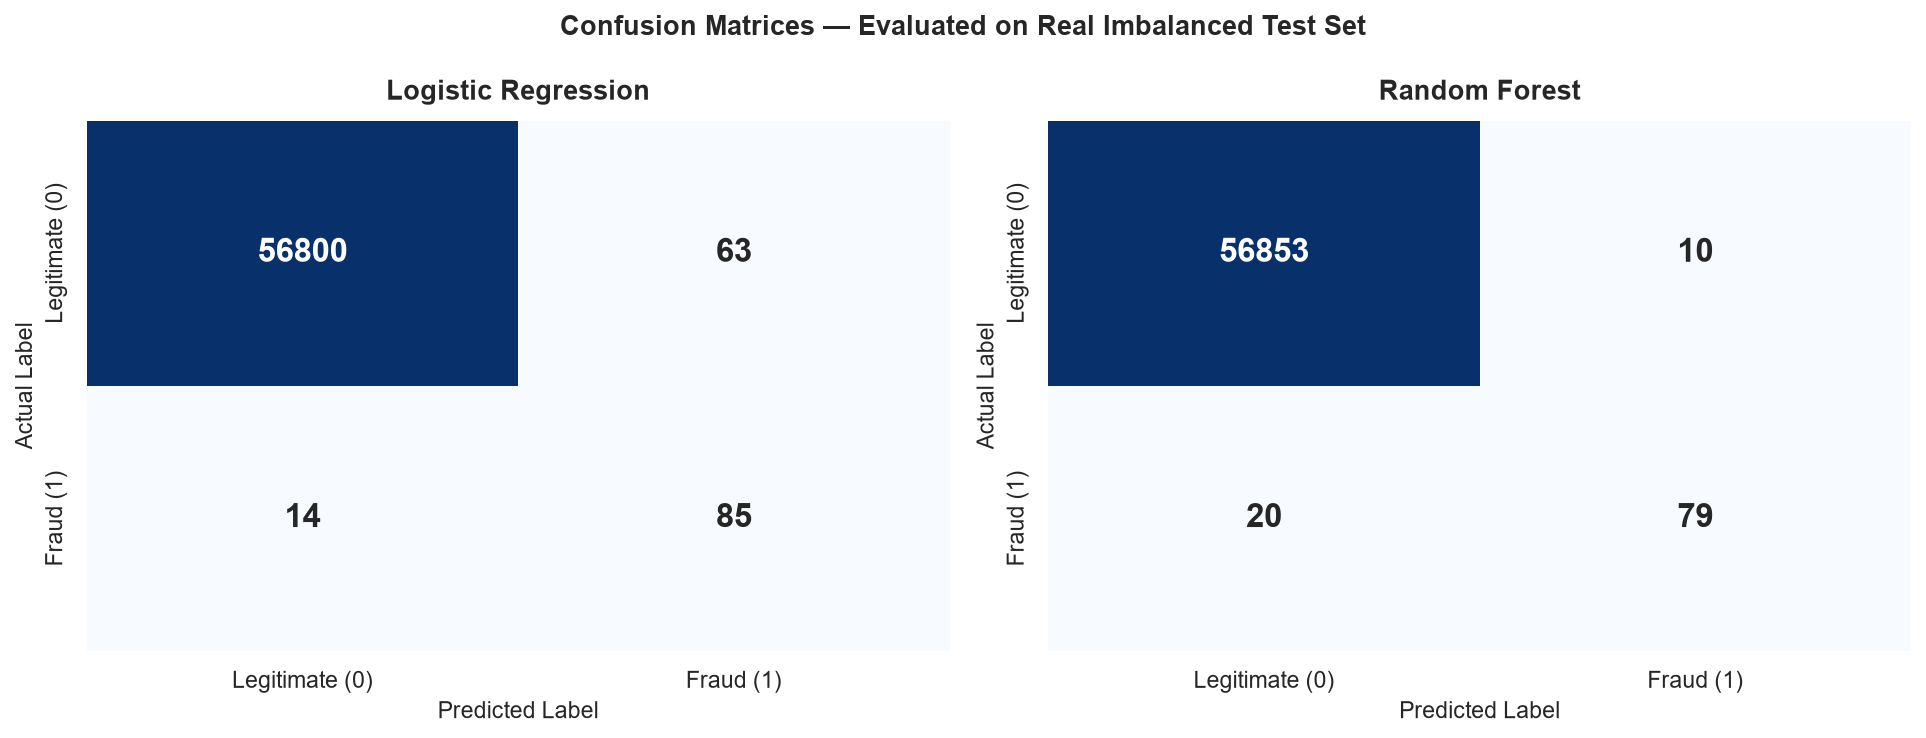

Chart saved -> graphs/03_confusion_matrices.png


In [73]:
fig, axes = plt.subplots(1, 2, figsize=(13, 5))

for ax, m in zip(axes, [metrics_lr, metrics_rf]):
    sns.heatmap(
        m['CM'], annot=True, fmt='d', cmap='Blues', cbar=False, ax=ax,
        annot_kws={'size': 16, 'weight': 'bold'}
    )
    ax.set_title(m['Model'], fontsize=13, fontweight='bold', pad=10)
    ax.set_xlabel('Predicted Label', fontsize=11)
    ax.set_ylabel('Actual Label', fontsize=11)
    ax.set_xticklabels(['Legitimate (0)', 'Fraud (1)'])
    ax.set_yticklabels(['Legitimate (0)', 'Fraud (1)'])

plt.suptitle('Confusion Matrices — Evaluated on Real Imbalanced Test Set', fontsize=13, fontweight='bold')
plt.tight_layout()
plt.savefig('graphs/03_confusion_matrices.png', bbox_inches='tight')
plt.show()
print("Chart saved -> graphs/03_confusion_matrices.png")

## Cell 11 — ROC Curves

The **Receiver Operating Characteristic (ROC) curve** plots True Positive Rate (Recall) against the
False Positive Rate at all classification thresholds. A model with **AUC closer to 1.0** is better.
The diagonal dashed line represents a random classifier (AUC = 0.5).

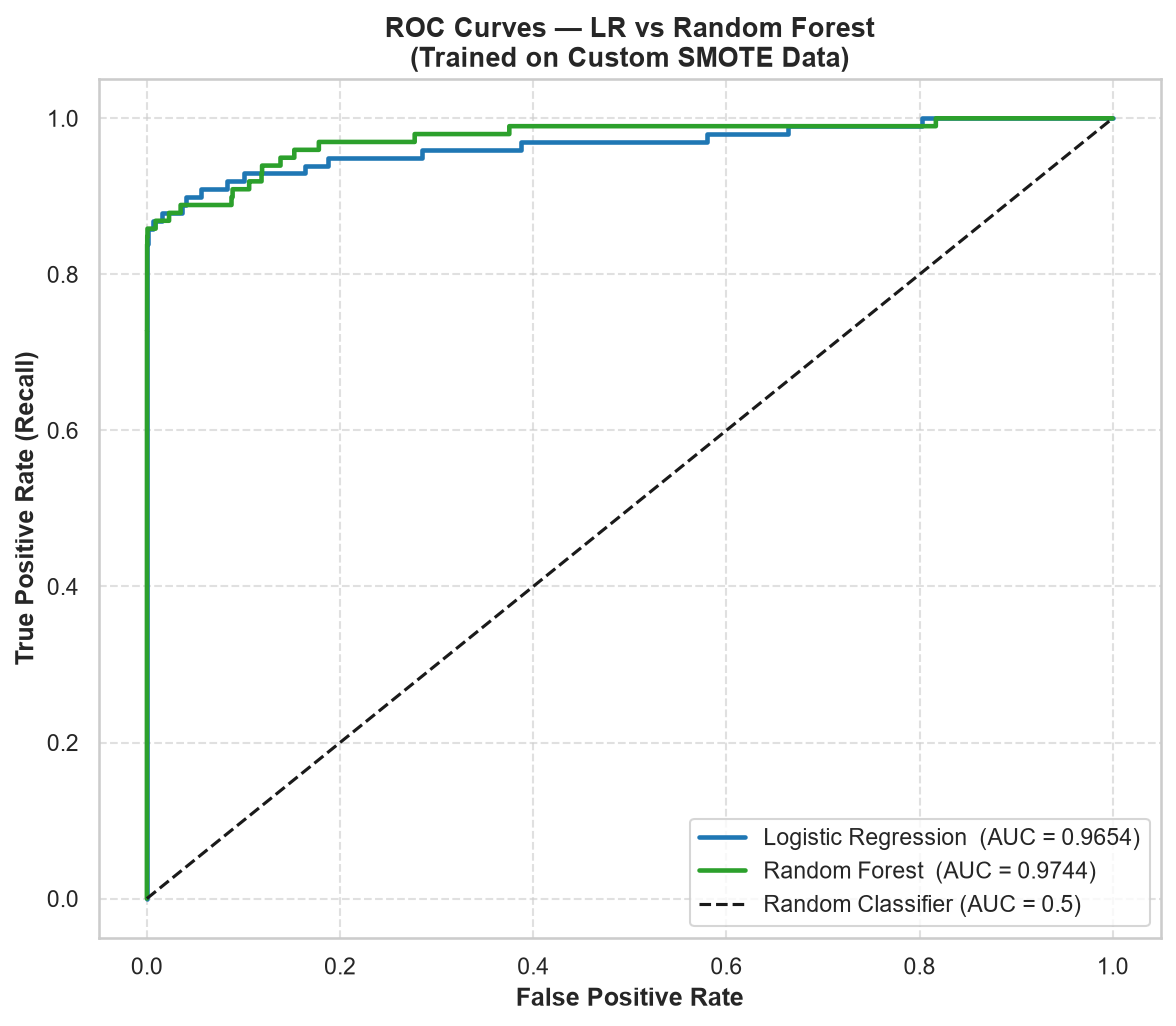

Chart saved -> graphs/04_roc_curves.png


In [74]:
plt.figure(figsize=(8, 7))

for m, prob, color in [
    (metrics_lr, y_prob_lr, '#1f77b4'),
    (metrics_rf, y_prob_rf, '#2ca02c')
]:
    fpr, tpr, _ = roc_curve(y_test, prob)
    plt.plot(fpr, tpr, lw=2.2, color=color,
             label=f"{m['Model']}  (AUC = {m['ROC-AUC']:.4f})")

plt.plot([0, 1], [0, 1], 'k--', lw=1.5, label='Random Classifier (AUC = 0.5)')
plt.xlabel('False Positive Rate', fontsize=12, fontweight='bold')
plt.ylabel('True Positive Rate (Recall)', fontsize=12, fontweight='bold')
plt.title('ROC Curves — LR vs Random Forest\n(Trained on Custom SMOTE Data)', fontsize=13, fontweight='bold')
plt.legend(loc='lower right', fontsize=11)
plt.grid(True, linestyle='--', alpha=0.6)
plt.tight_layout()
plt.savefig('graphs/04_roc_curves.png', bbox_inches='tight')
plt.show()
print("Chart saved -> graphs/04_roc_curves.png")

## Cell 12 — Precision-Recall Curves

For highly imbalanced datasets, the **Precision-Recall (PR) curve** is more informative than ROC
because it focuses only on the minority (fraud) class. A high PR-AUC indicates the model can maintain
good precision even as it tries to capture more frauds.

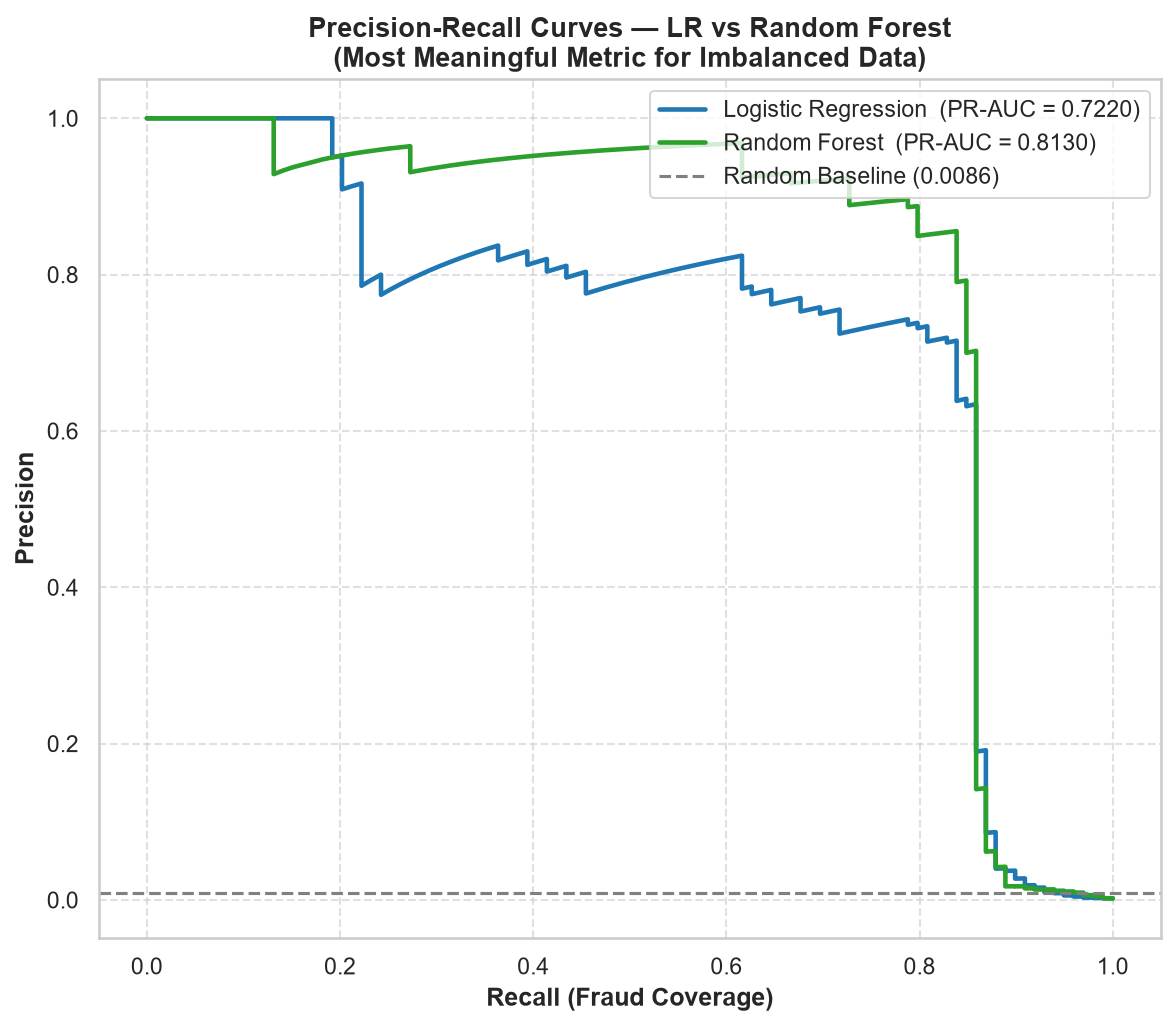

Chart saved -> graphs/05_pr_curves.png


In [75]:
plt.figure(figsize=(8, 7))

for m, prob, color in [
    (metrics_lr, y_prob_lr, '#1f77b4'),
    (metrics_rf, y_prob_rf, '#2ca02c')
]:
    prec_c, rec_c, _ = precision_recall_curve(y_test, prob)
    plt.plot(rec_c, prec_c, lw=2.2, color=color,
             label=f"{m['Model']}  (PR-AUC = {m['PR-AUC']:.4f})")

baseline = n_fraud / len(y_test)
plt.axhline(y=baseline, color='gray', linestyle='--', lw=1.5, label=f'Random Baseline ({baseline:.4f})')
plt.xlabel('Recall (Fraud Coverage)', fontsize=12, fontweight='bold')
plt.ylabel('Precision', fontsize=12, fontweight='bold')
plt.title('Precision-Recall Curves — LR vs Random Forest\n(Most Meaningful Metric for Imbalanced Data)', fontsize=13, fontweight='bold')
plt.legend(loc='upper right', fontsize=11)
plt.grid(True, linestyle='--', alpha=0.6)
plt.tight_layout()
plt.savefig('graphs/05_pr_curves.png', bbox_inches='tight')
plt.show()
print("Chart saved -> graphs/05_pr_curves.png")

## Cell 13 — Side-by-Side Metrics Comparison Bar Chart

A grouped bar chart comparing all key metrics across both models at a glance.

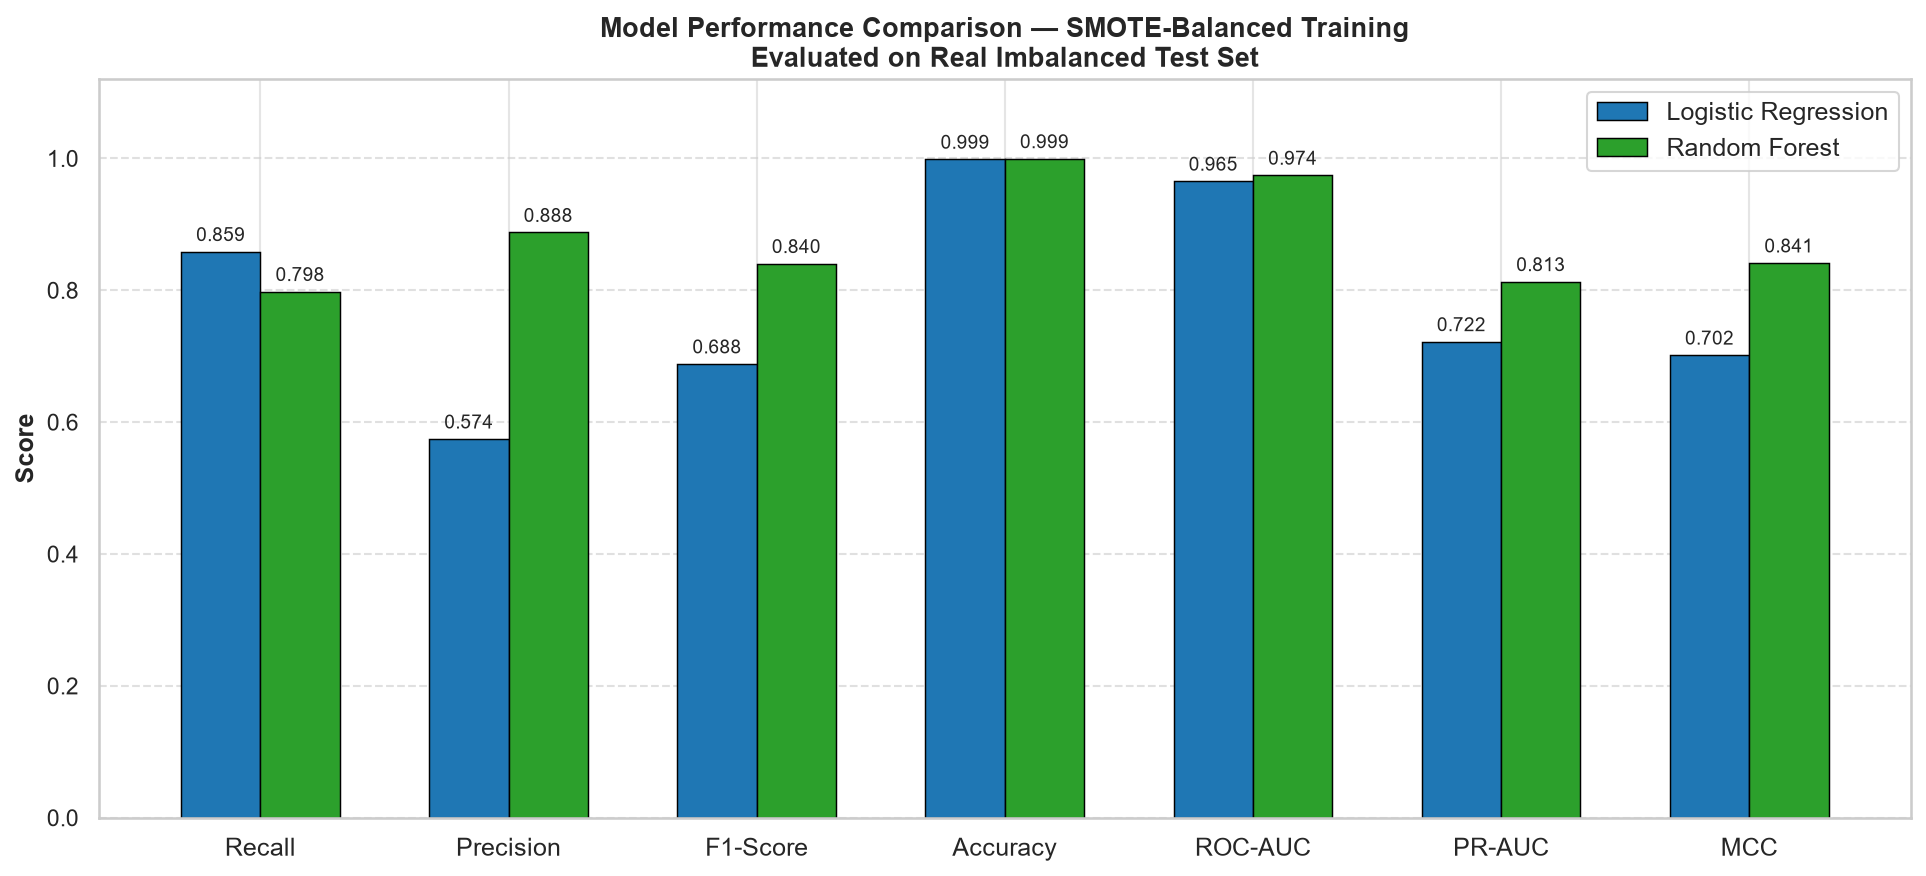

Chart saved -> graphs/06_metrics_comparison.png


In [76]:
metric_names = ['Recall', 'Precision', 'F1-Score', 'Accuracy', 'ROC-AUC', 'PR-AUC', 'MCC']
lr_vals = [metrics_lr[m] for m in metric_names]
rf_vals = [metrics_rf[m] for m in metric_names]

x = np.arange(len(metric_names))
w = 0.32

fig, ax = plt.subplots(figsize=(13, 6))
bars_lr = ax.bar(x - w/2, lr_vals, w, label='Logistic Regression', color='#1f77b4', edgecolor='black', linewidth=0.7)
bars_rf = ax.bar(x + w/2, rf_vals, w, label='Random Forest',        color='#2ca02c', edgecolor='black', linewidth=0.7)

ax.set_xticks(x)
ax.set_xticklabels(metric_names, fontsize=12)
ax.set_ylabel('Score', fontsize=12, fontweight='bold')
ax.set_ylim(0, 1.12)
ax.set_title('Model Performance Comparison — SMOTE-Balanced Training\nEvaluated on Real Imbalanced Test Set', fontsize=13, fontweight='bold')
ax.legend(fontsize=12)
ax.grid(axis='y', linestyle='--', alpha=0.6)

# Annotate bars
for bar in list(bars_lr) + list(bars_rf):
    ax.text(bar.get_x() + bar.get_width()/2, bar.get_height() + 0.01,
            f'{bar.get_height():.3f}', ha='center', va='bottom', fontsize=9)

plt.tight_layout()
plt.savefig('graphs/06_metrics_comparison.png', bbox_inches='tight')
plt.show()
print("Chart saved -> graphs/06_metrics_comparison.png")

## Cell 14 — Final Summary

We present the complete performance table of both models trained on the mathematical SMOTE-balanced dataset
and evaluated on the real imbalanced test set.

In [77]:
print("=" * 85)
print("FINAL EVALUATION SUMMARY — Math SMOTE + ML Models")
print("=" * 85)
print(f"{'Metric':<18} {'Logistic Regression':>22} {'Random Forest':>18}")
print("-" * 62)
for col in ['Recall', 'Precision', 'F1-Score', 'Accuracy', 'MCC', 'ROC-AUC', 'PR-AUC']:
    print(f"{col:<18} {metrics_lr[col]:>22.4f} {metrics_rf[col]:>18.4f}")
print("-" * 62)
print(f"{'TP (Fraud Caught)':<18} {metrics_lr['TP']:>22d} {metrics_rf['TP']:>18d}")
print(f"{'FN (Fraud Missed)':<18} {metrics_lr['FN']:>22d} {metrics_rf['FN']:>18d}")
print(f"{'FP (False Alarms)':<18} {metrics_lr['FP']:>22d} {metrics_rf['FP']:>18d}")
print(f"{'TN (Legit Cleared)':<18} {metrics_lr['TN']:>22d} {metrics_rf['TN']:>18d}")
print("=" * 85)

FINAL EVALUATION SUMMARY — Math SMOTE + ML Models
Metric                Logistic Regression      Random Forest
--------------------------------------------------------------
Recall                             0.8586             0.7980
Precision                          0.5743             0.8876
F1-Score                           0.6883             0.8404
Accuracy                           0.9986             0.9995
MCC                                0.7016             0.8414
ROC-AUC                            0.9654             0.9744
PR-AUC                             0.7220             0.8130
--------------------------------------------------------------
TP (Fraud Caught)                      85                 79
FN (Fraud Missed)                      14                 20
FP (False Alarms)                      63                 10
TN (Legit Cleared)                  56800              56853
